In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

album = pd.read_csv("Album.csv")
artist= pd.read_csv("Artist.csv")
customer = pd.read_csv("Customer.csv")
employee = pd.read_csv("Employee.csv")
genre = pd.read_csv("Genre.csv")
invoice = pd.read_csv("Invoice.csv")
invoice_line = pd.read_csv("InvoiceLine.csv")
media = pd.read_csv("MediaType.csv")
playlist = pd.read_csv("Playlist.csv")
playlist_track = pd.read_csv("PlayListTrack.csv")
track = pd.read_csv("Track.csv")


# Usamos solo invoice, pero preparamos la fecha
df_ventas = invoice.copy()
df_ventas['InvoiceDate'] = pd.to_datetime(df_ventas['InvoiceDate'])
df_ventas['Mes_Año'] = df_ventas['InvoiceDate'].dt.to_period('M')

# Agrupar las ventas totales por mes
ventas_mensuales = df_ventas.groupby('Mes_Año')['Total'].sum()
display(ventas_mensuales.head(2))
# Convertir el índice (period) a string para que matplotlib lo grafique sin problemas
ventas_mensuales.index = ventas_mensuales.index.astype(str)
display(ventas_mensuales.head(2))

# Cruzar Tracks con Media Types para tener el nombre del formato
df_pistas_media = pd.merge(track, media, on="MediaTypeId", suffixes=('_Track', '_Media'))

# Convertir milisegundos a minutos y bytes a megabytes
df_pistas_media['Minutos'] = df_pistas_media['Milliseconds'] / 60000
df_pistas_media['Megabytes'] = df_pistas_media['Bytes'] / (1024 * 1024)

# Filtrar valores atípicos extremos para una mejor visualización
df_scatter = df_pistas_media[df_pistas_media['Minutos'] < 20]
df_scatter.head()


# Cruzar líneas de factura con canciones y luego con géneros
df_inv_trk = pd.merge(invoice_line, track, on="TrackId")
df_ventas_generos = pd.merge(df_inv_trk, genre, on="GenreId", suffixes=('_Track', '_Genre'))

# Sumar las ventas (Quantity * UnitPrice) por género
df_ventas_generos['Monto'] = df_ventas_generos['UnitPrice_x'] * df_ventas_generos['Quantity']
ingresos_por_genero = df_ventas_generos.groupby('Name_Genre')['Monto'].sum().sort_values(ascending=False)

# Tomar el top 5
top_5_generos = ingresos_por_genero.head(5)
top_5_generos

#storytelling of barchers leerlo (estrategia de ventas) 

Mes_Año
2021-01    35.64
2021-02    37.62
Freq: M, Name: Total, dtype: float64

Mes_Año
2021-01    35.64
2021-02    37.62
Name: Total, dtype: float64

Name_Genre
Rock                  826.65
Latin                 382.14
Metal                 261.36
Alternative & Punk    241.56
TV Shows               93.53
Name: Monto, dtype: float64

# Ejercicios


### Con el Dataframe `customer`, haz un `countplot` horizontal del número de clientes por país, ordenado de mayor a menor 

<class 'pandas.DataFrame'>
RangeIndex: 8 entries, 0 to 7
Data columns (total 15 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   EmployeeId  8 non-null      int64  
 1   LastName    8 non-null      str    
 2   FirstName   8 non-null      str    
 3   Title       8 non-null      str    
 4   ReportsTo   7 non-null      float64
 5   BirthDate   8 non-null      str    
 6   HireDate    8 non-null      str    
 7   Address     8 non-null      str    
 8   City        8 non-null      str    
 9   State       8 non-null      str    
 10  Country     8 non-null      str    
 11  PostalCode  8 non-null      str    
 12  Phone       8 non-null      str    
 13  Fax         8 non-null      str    
 14  Email       8 non-null      str    
dtypes: float64(1), int64(1), str(13)
memory usage: 1.1 KB
Index(['USA', 'Canada', 'France', 'Brazil', 'Germany'], dtype='str', name='Country')


<Axes: xlabel='count', ylabel='Country'>

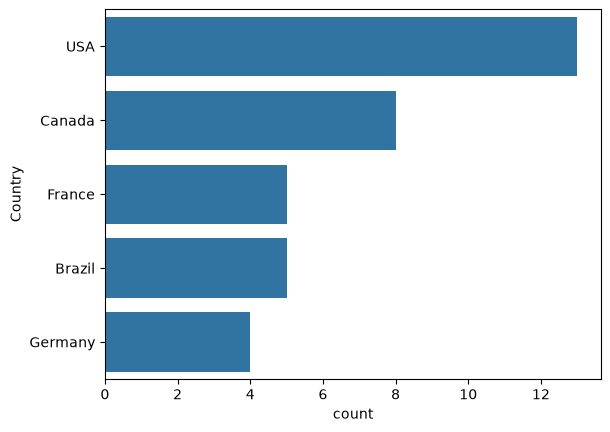

In [ ]:
customer.info()

clientes_por_pais = customer.groupby('Country')['CustomerId'].count().sort_values(ascending=False).head(5).index

print(clientes_por_pais)

sns.countplot(data= customer, y ="Country", order= clientes_por_pais)



### 2. Haz un `boxplot` del `Total` de las facturas por país, solo para los 5 países con más ingresos.
### ¿Algún país tiene facturas atípicamente grandes?

<class 'pandas.DataFrame'>
RangeIndex: 412 entries, 0 to 411
Data columns (total 9 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   InvoiceId          412 non-null    int64  
 1   CustomerId         412 non-null    int64  
 2   InvoiceDate        412 non-null    str    
 3   BillingAddress     412 non-null    str    
 4   BillingCity        412 non-null    str    
 5   BillingState       210 non-null    str    
 6   BillingCountry     412 non-null    str    
 7   BillingPostalCode  384 non-null    str    
 8   Total              412 non-null    float64
dtypes: float64(1), int64(2), str(6)
memory usage: 29.1 KB
Index(['USA', 'Canada', 'France', 'Brazil', 'Germany'], dtype='str', name='BillingCountry')


<Axes: xlabel='BillingCountry', ylabel='Total'>

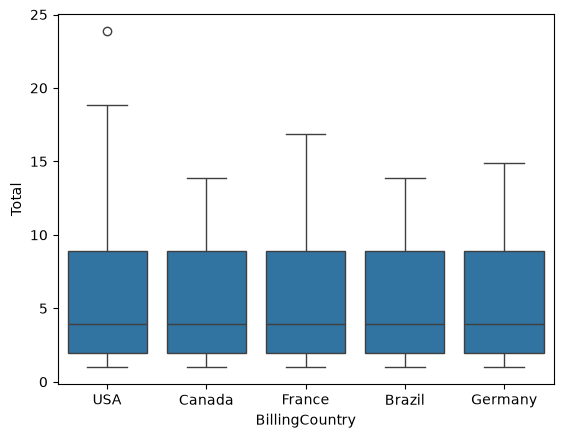

In [31]:
invoice.info()
facturas_por_pais = invoice.groupby("BillingCountry")["InvoiceId"].count().sort_values(ascending=False).head(5).index
print(facturas_por_pais)

sns.boxplot(data= invoice, x="BillingCountry", y="Total", order= facturas_por_pais)

#### Interpretación: `Estados Unidos` tiene una factura atipicamente grandes 

### 3. Une `invoice` con `customer` (por `CustomerId`) y luego con `emloyee` (`SupportRepId` de `customer` corresponde a `EmployeeId`; usa `left_on/right_on`) y grafica con `barplot` los ingresos totales que atiende cada representante de soporte.

In [35]:
union_facturas_con_clientes = invoice.merge(customer, on= "CustomerId")

union_facturas_con_clientes_y_empleados = union_facturas_con_clientes.merge(
    employee,
    left_on= "SupportRepId",
    right_on= "EmployeeId",
    suffixes= ("Clientes", "Empleado")
)

display(union_facturas_con_clientes_y_empleados)


,InvoiceId,CustomerId,InvoiceDate,BillingAddress,BillingCity,BillingState,BillingCountry,BillingPostalCode,Total,FirstNameClientes,...,BirthDate,HireDate,AddressEmpleado,CityEmpleado,StateEmpleado,CountryEmpleado,PostalCodeEmpleado,PhoneEmpleado,FaxEmpleado,EmailEmpleado
0,1,2,2021-01-01 00:00:00,Theodor-Heuss-Straße 34,Stuttgart,NaN,Germany,70174,1.98,Leonie,...,1965-03-03 00:00:00,2003-10-17 00:00:00,7727B 41 Ave,Calgary,AB,Canada,T3B 1Y7,1 (780) 836-9987,1 (780) 836-9543,steve@chinookcorp.com
1,2,4,2021-01-02 00:00:00,Ullevålsveien 14,Oslo,NaN,Norway,0171,3.96,Bjørn,...,1947-09-19 00:00:00,2003-05-03 00:00:00,683 10 Street SW,Calgary,AB,Canada,T2P 5G3,+1 (403) 263-4423,+1 (403) 263-4289,margaret@chinookcorp.com
2,3,8,2021-01-03 00:00:00,Grétrystraat 63,Brussels,NaN,Belgium,1000,5.94,Daan,...,1947-09-19 00:00:00,2003-05-03 00:00:00,683 10 Street SW,Calgary,AB,Canada,T2P 5G3,+1 (403) 263-4423,+1 (403) 263-4289,margaret@chinookcorp.com
3,4,14,2021-01-06 00:00:00,8210 111 ST NW,Edmonton,AB,Canada,T6G 2C7,8.91,Mark,...,1965-03-03 00:00:00,2003-10-17 00:00:00,7727B 41 Ave,Calgary,AB,Canada,T3B 1Y7,1 (780) 836-9987,1 (780) 836-9543,steve@chinookcorp.com
4,5,23,2021-01-11 00:00:00,69 Salem Street,Boston,MA,USA,2113,13.86,John,...,1947-09-19 00:00:00,2003-05-03 00:00:00,683 10 Street SW,Calgary,AB,Canada,T2P 5G3,+1 (403) 263-4423,+1 (403) 263-4289,margaret@chinookcorp.com
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
407,408,25,2025-12-05 00:00:00,319 N. Frances Street,Madison,WI,USA,53703,3.96,Victor,...,1965-03-03 00:00:00,2003-10-17 00:00:00,7727B 41 Ave,Calgary,AB,Canada,T3B 1Y7,1 (780) 836-9987,1 (780) 836-9543,steve@chinookcorp.com
408,409,29,2025-12-06 00:00:00,796 Dundas Street West,Toronto,ON,Canada,M6J 1V1,5.94,Robert,...,1973-08-29 00:00:00,2002-04-01 00:00:00,1111 6 Ave SW,Calgary,AB,Canada,T2P 5M5,+1 (403) 262-3443,+1 (403) 262-6712,jane@chinookcorp.com
409,410,35,2025-12-09 00:00:00,"Rua dos Campeões Europeus de Viena, 4350",Porto,NaN,Portugal,NaN,8.91,Madalena,...,1947-09-19 00:00:00,2003-05-03 00:00:00,683 10 Street SW,Calgary,AB,Canada,T2P 5G3,+1 (403) 263-4423,+1 (403) 263-4289,margaret@chinookcorp.com
410,411,44,2025-12-14 00:00:00,Porthaninkatu 9,Helsinki,NaN,Finland,00530,13.86,Terhi,...,1973-08-29 00:00:00,2002-04-01 00:00:00,1111 6 Ave SW,Calgary,AB,Canada,T2P 5M5,+1 (403) 262-3443,+1 (403) 262-6712,jane@chinookcorp.com
